# Árvores de Decisão para Estimativa do Preço de Casas

> Alan Hoffmann Dos Santos

Neste notebook será construído um modelo de **regressão** para a competição *House Prices – Advanced Regression Techniques* (Kaggle), utilizando as características das residências para estimar o preço de venda em **dólares**.

Os conjuntos `train.csv` e `test.csv` possuem, respectivamente, 1.460 e 1.459 casas da cidade de Ames (Iowa, EUA), descritas por 79 variáveis. A variável `SalePrice` será utilizada como variável-alvo.

A competição avalia as submissões pelo **RMSE entre o logaritmo do preço previsto e o logaritmo do preço observado**.

Objetivos:
- carregar e verificar o conjunto de dados;
- tratar valores ausentes e outliers sem utilizar informações do conjunto de teste;
- criar novas variáveis a partir das existentes;
- treinar uma árvore de decisão e otimizar seus hiperparâmetros;
- comparar a árvore com ensembles de árvores (Random Forest, Gradient Boosting, XGBoost e LightGBM);
- comparar otimizadores em uma rede neural;
- combinar os melhores modelos em um ensemble;
- avaliar todos os modelos com validação cruzada, usando a métrica da competição;
- gerar o arquivo de submissão.


In [1]:
!pip install -q xgboost lightgbm


In [2]:
import os
import time
import random
import warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from scipy.stats import skew
from scipy.special import boxcox1p
from scipy.optimize import nnls
from sklearn.base import clone
from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.linear_model import Lasso, ElasticNet, RidgeCV
from sklearn.kernel_ridge import KernelRidge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


## 1. Carregamento dos dados

Os arquivos devem estar no diretório de trabalho do notebook. No Google Colab, faça o upload de `train.csv` e `test.csv` ou monte o Google Drive.


In [3]:
CAMINHO = '/content/' if os.path.exists('/content/train.csv') else ''

train = pd.read_csv(CAMINHO + 'train.csv')
test = pd.read_csv(CAMINHO + 'test.csv')

print(f"Treino: {train.shape[0]} linhas x {train.shape[1]} colunas")
print(f"Teste:  {test.shape[0]} linhas x {test.shape[1]} colunas")
display(train.head())


Treino: 1460 linhas x 81 colunas
Teste:  1459 linhas x 80 colunas


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
print(f'Linhas duplicadas no treino: {train.duplicated().sum()}')

ausentes = pd.DataFrame({'treino': train.isna().sum(), 'teste': test.isna().sum()})
ausentes = ausentes[ausentes.sum(axis=1) > 0].sort_values('treino', ascending=False)
print(f'Colunas com valores ausentes: {len(ausentes)}')
display(ausentes)


Linhas duplicadas no treino: 0
Colunas com valores ausentes: 34


,treino,teste
PoolQC,1453,1456.0
MiscFeature,1406,1408.0
Alley,1369,1352.0
Fence,1179,1169.0
MasVnrType,872,894.0
FireplaceQu,690,730.0
LotFrontage,259,227.0
GarageFinish,81,78.0
GarageCond,81,78.0
GarageYrBlt,81,78.0


## 2. Definição do problema

A variável que queremos estimar é `SalePrice`, o preço de venda da casa em dólares.

O problema é, portanto, de **regressão supervisionada**: a saída do modelo é um valor numérico contínuo.

A métrica da competição é:

\[ RMSE_{log} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(\log(\hat{y}_i) - \log(y_i)\right)^2} \]

Como o erro é medido em logaritmo, errar 10% numa casa de US$ 100 mil pesa o mesmo que errar 10% numa casa de US$ 500 mil. Por isso, o modelo será treinado diretamente com o alvo transformado:

\[ y = \log(1 + SalePrice) \]

Ao final, as previsões voltam para dólares com a transformação inversa, \( SalePrice = e^{y} - 1 \).


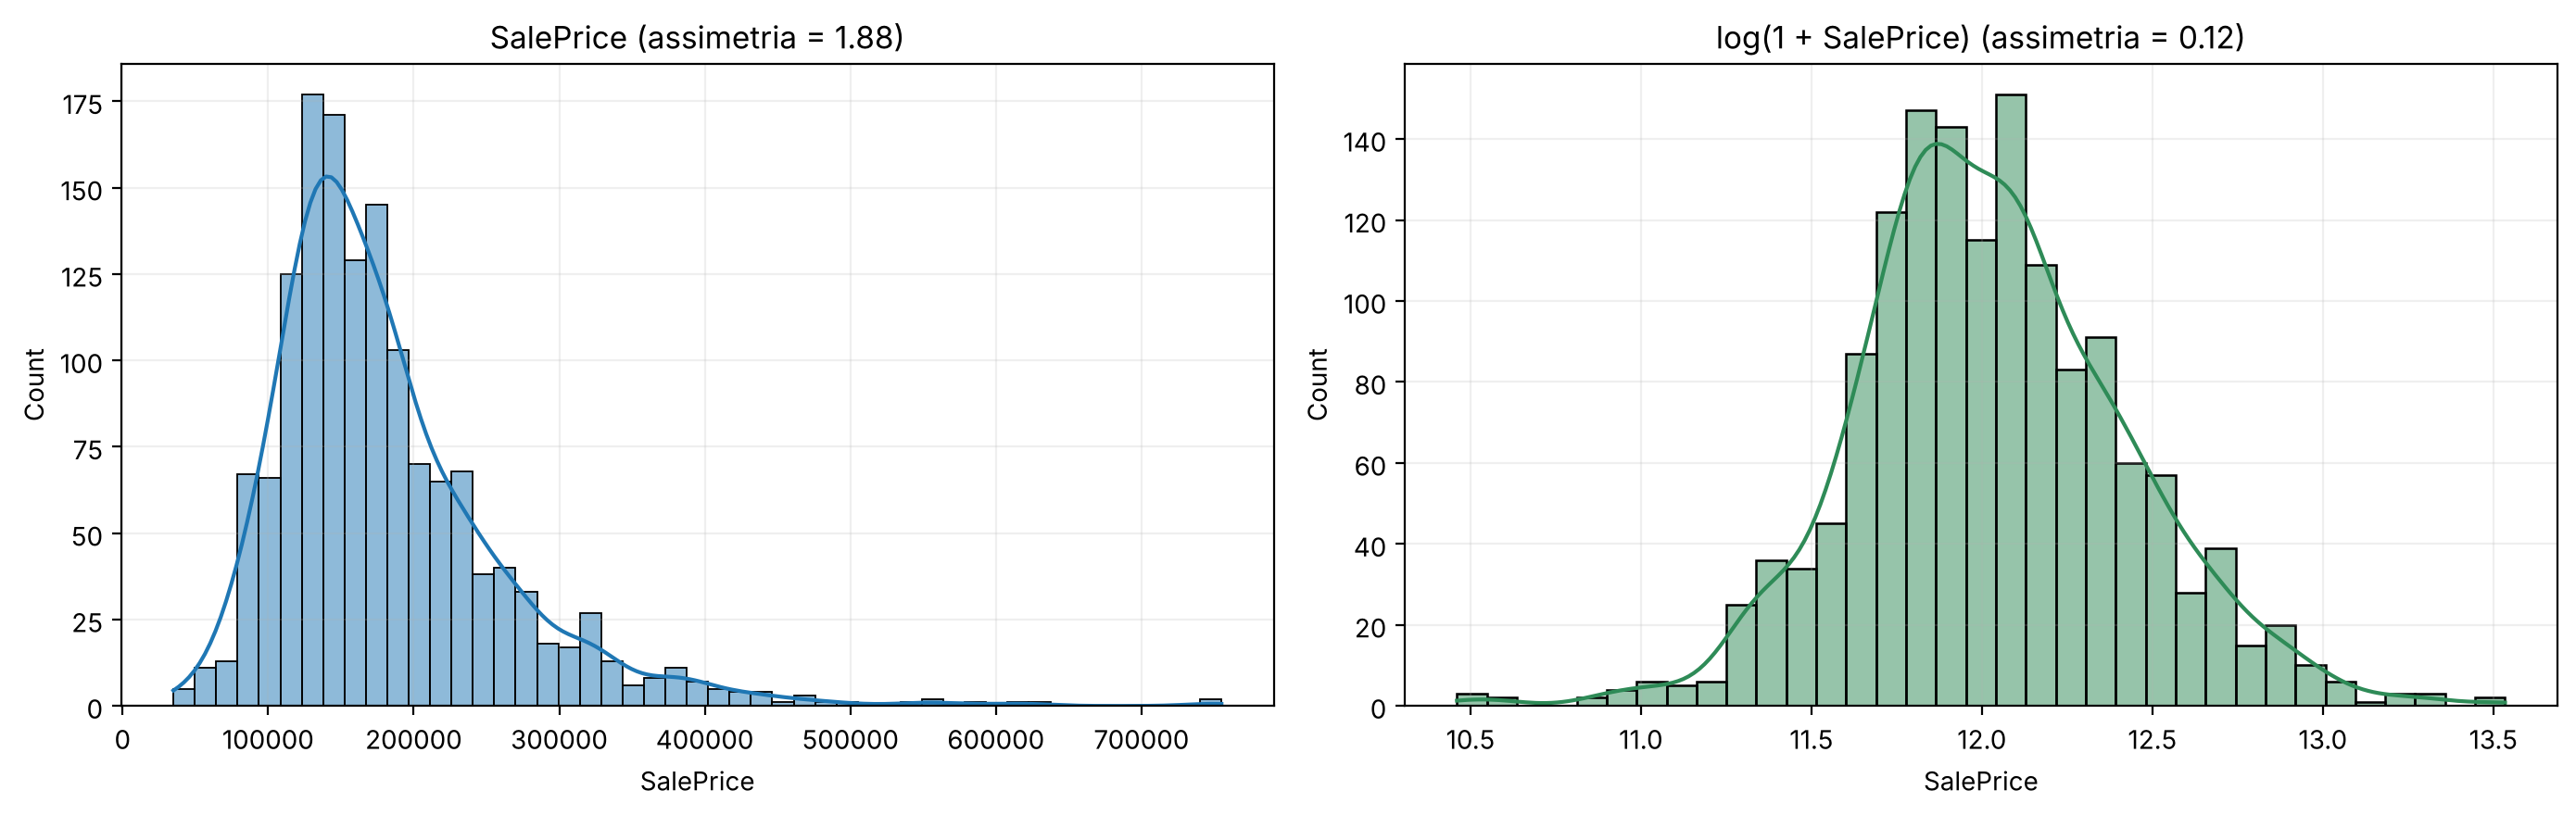

In [5]:
TARGET = 'SalePrice'

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(train[TARGET], kde=True, ax=axes[0])
axes[0].set_title(f'SalePrice (assimetria = {train[TARGET].skew():.2f})')
sns.histplot(np.log1p(train[TARGET]), kde=True, ax=axes[1], color='seagreen')
axes[1].set_title(f'log(1 + SalePrice) (assimetria = {np.log1p(train[TARGET]).skew():.2f})')
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 3. Análise exploratória

A análise exploratória completa está no notebook dos passos 1 a 12. Aqui são retomadas as relações mais fortes com o preço, que orientam a criação de novas variáveis.


,correlação com SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


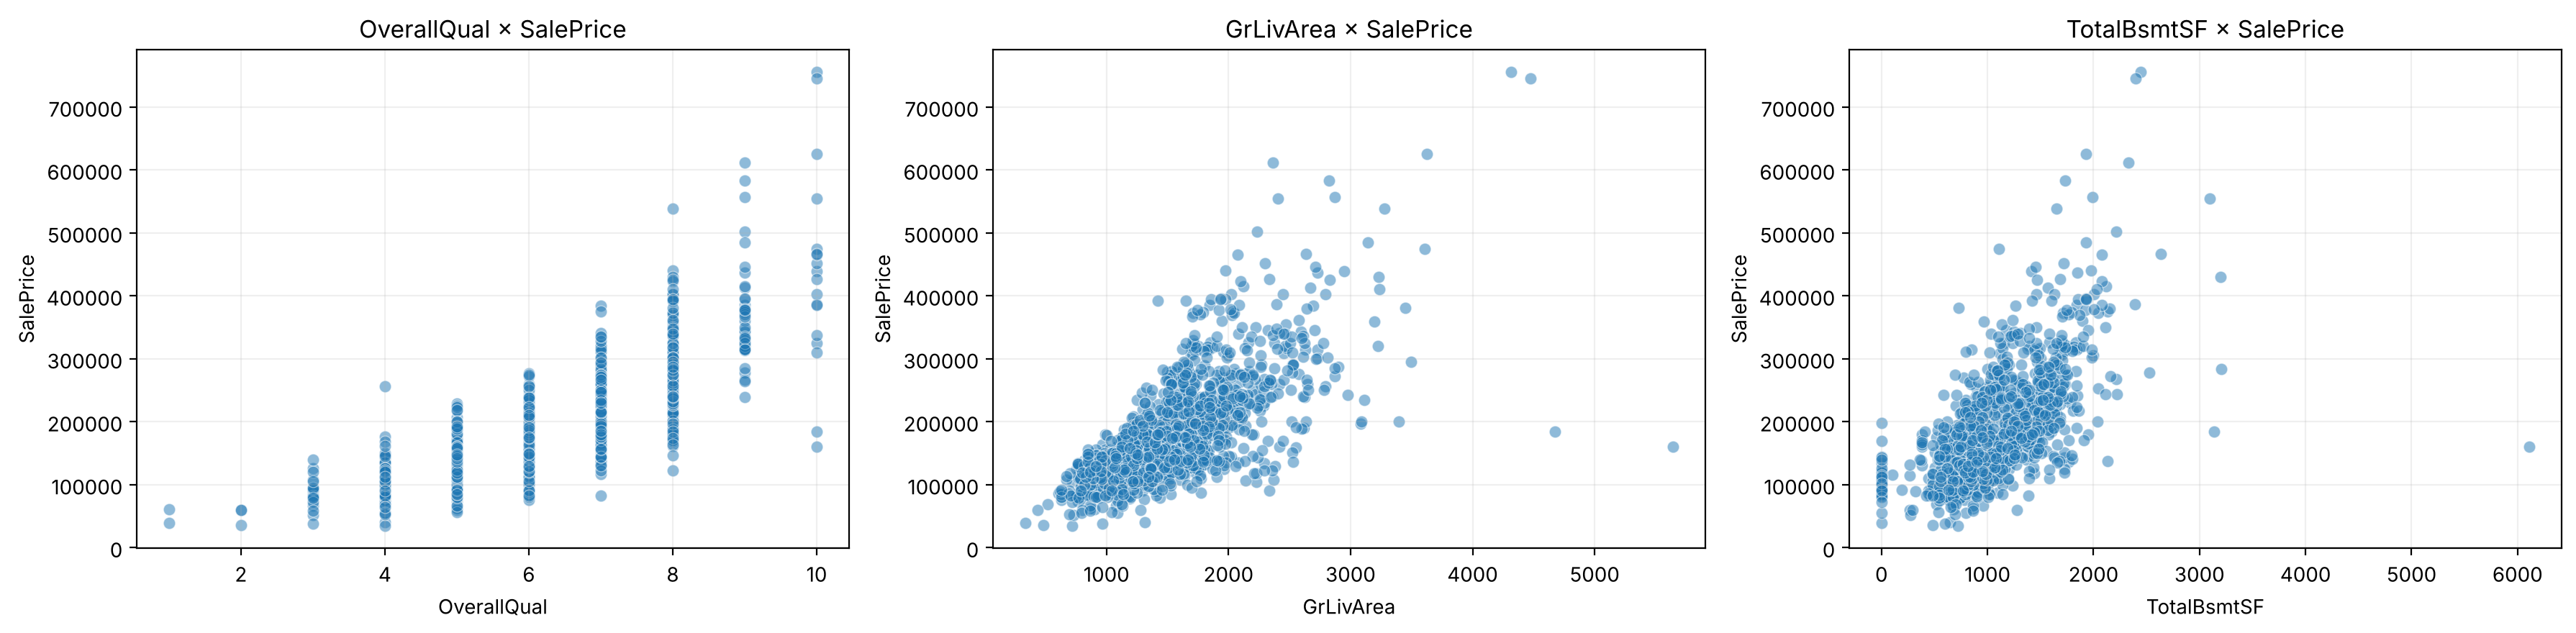

In [6]:
corr = train.corr(numeric_only=True)[TARGET].drop(TARGET).sort_values(ascending=False)
display(corr.head(10).to_frame('correlação com SalePrice'))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ['OverallQual', 'GrLivArea', 'TotalBsmtSF']):
    sns.scatterplot(data=train, x=col, y=TARGET, ax=ax, alpha=0.5)
    ax.set_title(f'{col} × {TARGET}')
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 4. Remoção de outliers

No gráfico `GrLivArea × SalePrice` aparecem **2 casas com mais de 4.000 pés² vendidas por menos de US$ 300 mil**. Elas fogem completamente do padrão e o próprio autor do conjunto de dados (De Cock, 2011) recomenda removê-las.

As demais casas caras **permanecem**: são casas de alta qualidade, e o modelo precisa aprender com elas.


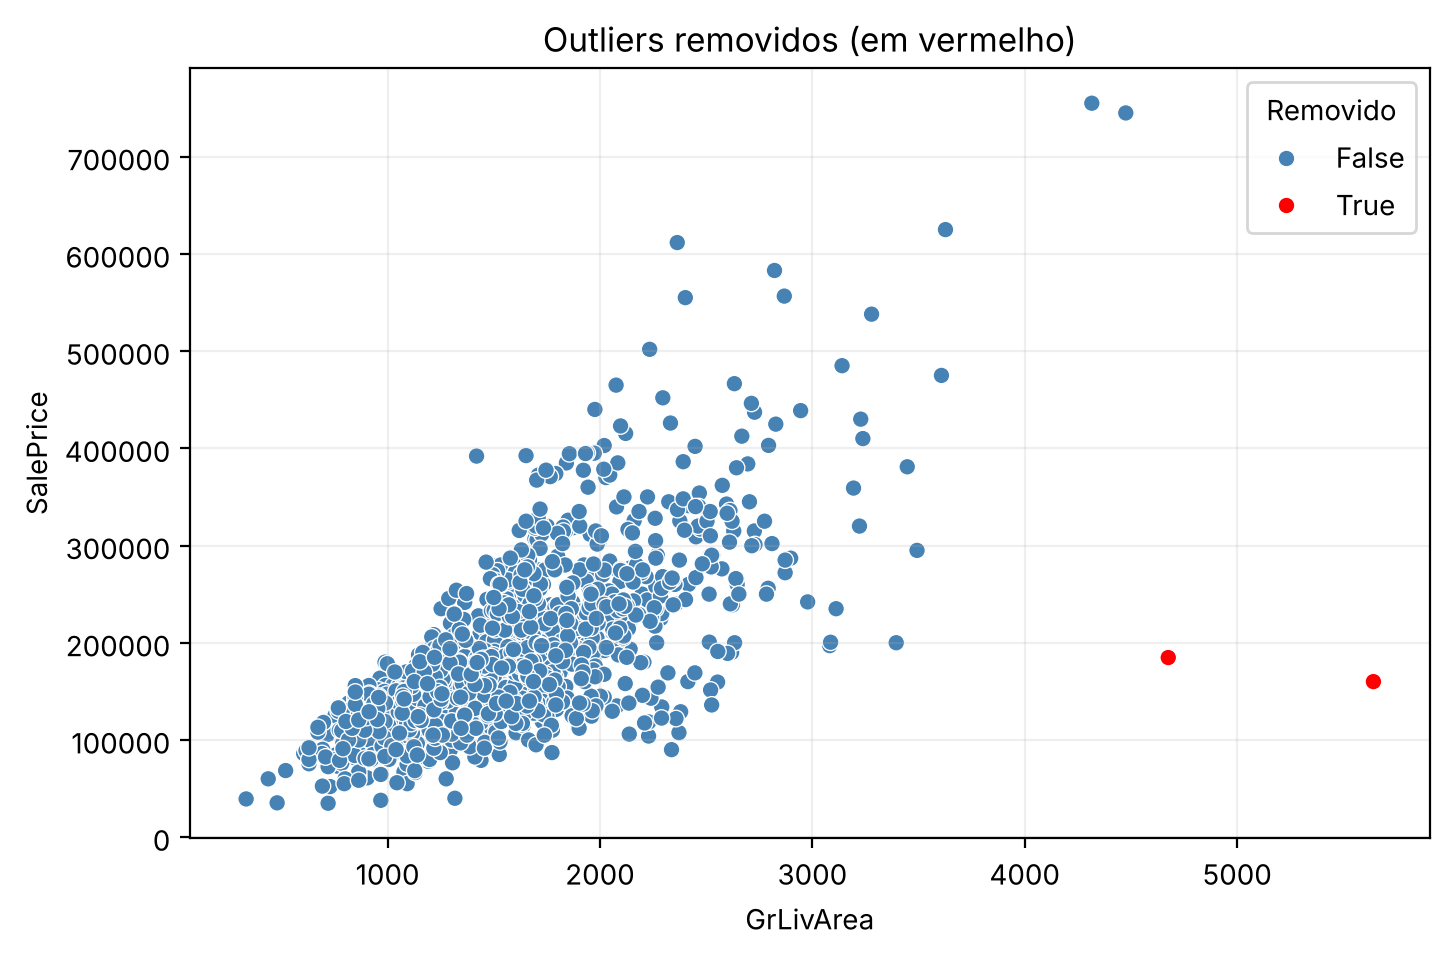

Casas removidas: 2
Treino após a remoção: 1458 casas


In [7]:
outliers = (train['GrLivArea'] > 4000) & (train[TARGET] < 300000)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=train, x='GrLivArea', y=TARGET, hue=outliers,
                palette={False: 'steelblue', True: 'red'})
plt.title('Outliers removidos (em vermelho)')
plt.legend(title='Removido')
plt.grid(alpha=0.2)
plt.show()

train = train.loc[~outliers].reset_index(drop=True)
y = np.log1p(train[TARGET]).values

print(f'Casas removidas: {outliers.sum()}')
print(f'Treino após a remoção: {len(train)} casas')


## 5. Tratamento dos valores ausentes

Treino e teste recebem **as mesmas regras**. Toda estatística usada para preencher valores (mediana, moda) é calculada **somente com o conjunto de treinamento**, assim como a padronização do notebook de redes neurais.

| Situação | Tratamento |
|---|---|
| NA significa "não possui" (sem piscina, porão, garagem, lareira...) | categoria `'None'` |
| Áreas e contagens dessas estruturas | `0` |
| Ano de construção da garagem | ano de construção da casa |
| Frente do terreno (`LotFrontage`) | mediana do bairro no treino |
| Zoneamento (`MSZoning`) | moda do tipo de casa no treino |
| Funcionalidade (`Functional`) | `'Typ'` (o dicionário de dados manda assumir "típica") |
| Demais casos (poucas casas) | moda do treino |


In [8]:
n_train = len(train)
test_id = test['Id']
dados = pd.concat([train.drop(columns=TARGET), test]).reset_index(drop=True).drop(columns='Id')
treino_ref = dados.iloc[:n_train].copy()   # referência: estatísticas só do treino

nao_possui = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'GarageType', 'GarageFinish',
              'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
              'BsmtFinType2', 'MasVnrType']
dados[nao_possui] = dados[nao_possui].fillna('None')

zero = ['MasVnrArea', 'GarageCars', 'GarageArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
        'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']
dados[zero] = dados[zero].fillna(0)

dados['GarageYrBlt'] = dados['GarageYrBlt'].fillna(dados['YearBuilt'])

mediana_bairro = treino_ref.groupby('Neighborhood')['LotFrontage'].median()
dados['LotFrontage'] = dados['LotFrontage'].fillna(dados['Neighborhood'].map(mediana_bairro))

moda_zona = treino_ref.groupby('MSSubClass')['MSZoning'].agg(lambda s: s.mode()[0])
dados['MSZoning'] = dados['MSZoning'].fillna(dados['MSSubClass'].map(moda_zona))

dados['Functional'] = dados['Functional'].fillna('Typ')

for coluna in dados.columns[dados.isna().any()]:
    dados[coluna] = dados[coluna].fillna(treino_ref[coluna].mode()[0])

# Colunas praticamente constantes não ajudam o modelo
print('Utilities:', treino_ref['Utilities'].value_counts().to_dict())
print('Street:   ', treino_ref['Street'].value_counts().to_dict())
print('PoolQC:   ', (treino_ref['PoolQC'].notna()).sum(), 'casas com piscina')
dados = dados.drop(columns=['Utilities', 'Street', 'PoolQC'])

assert dados.isna().sum().sum() == 0
print(f'\nValores ausentes restantes: {dados.isna().sum().sum()}')


Utilities: {'AllPub': 1457, 'NoSeWa': 1}
Street:    {'Pave': 1452, 'Grvl': 6}
PoolQC:    6 casas com piscina

Valores ausentes restantes: 0


## 6. Engenharia de atributos

**a) Códigos que não são quantidades.** `MSSubClass` (tipo da casa), `MoSold` e `YrSold` são números, mas representam categorias.

**b) Escalas ordinais.** As variáveis de qualidade têm ordem natural (Po < Fa < TA < Gd < Ex) e são convertidas para 0–5.

**c) Novas variáveis.** Informações espalhadas em várias colunas são combinadas:

| Variável | Definição |
|---|---|
| `TotalSF` | área do porão + 1º andar + 2º andar |
| `TotalBath` | banheiros completos + 0,5 × lavabos (incluindo porão) |
| `TotalPorch` | soma das áreas de varandas e deck |
| `HouseAge` / `RemodAge` | idade da casa / da reforma no ano da venda |
| `QualSF` / `QualTotSF` | qualidade geral × área (área útil / área total) |
| `Has...` | indicadores 0/1: possui piscina, 2º andar, garagem, porão, lareira |


In [9]:
for c in ['MSSubClass', 'MoSold', 'YrSold']:
    dados[c] = dados[c].astype(str)

qualidade = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
          'FireplaceQu', 'GarageQual', 'GarageCond']:
    dados[c] = dados[c].map(qualidade).astype(int)
dados['BsmtExposure'] = dados['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4})
acabamento = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
dados['BsmtFinType1'] = dados['BsmtFinType1'].map(acabamento)
dados['BsmtFinType2'] = dados['BsmtFinType2'].map(acabamento)
dados['GarageFinish'] = dados['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})
dados['Functional'] = dados['Functional'].map({'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3,
                                               'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7})
dados['CentralAir'] = (dados['CentralAir'] == 'Y').astype(int)

dados['TotalSF']      = dados['TotalBsmtSF'] + dados['1stFlrSF'] + dados['2ndFlrSF']
dados['TotalBath']    = (dados['FullBath'] + 0.5 * dados['HalfBath']
                         + dados['BsmtFullBath'] + 0.5 * dados['BsmtHalfBath'])
dados['TotalPorch']   = dados[['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'WoodDeckSF']].sum(axis=1)
dados['HouseAge']     = dados['YrSold'].astype(int) - dados['YearBuilt']
dados['RemodAge']     = dados['YrSold'].astype(int) - dados['YearRemodAdd']
dados['IsRemod']      = (dados['YearBuilt'] != dados['YearRemodAdd']).astype(int)
dados['QualSF']       = dados['OverallQual'] * dados['GrLivArea']
dados['QualTotSF']    = dados['OverallQual'] * dados['TotalSF']
dados['HasPool']      = (dados['PoolArea'] > 0).astype(int)
dados['Has2nd']       = (dados['2ndFlrSF'] > 0).astype(int)
dados['HasGarage']    = (dados['GarageArea'] > 0).astype(int)
dados['HasBsmt']      = (dados['TotalBsmtSF'] > 0).astype(int)
dados['HasFireplace'] = (dados['Fireplaces'] > 0).astype(int)

NOVAS = ['QualTotSF', 'QualSF', 'TotalSF', 'TotalBath', 'TotalPorch', 'HouseAge', 'RemodAge',
         'IsRemod', 'HasPool', 'Has2nd', 'HasGarage', 'HasBsmt', 'HasFireplace']


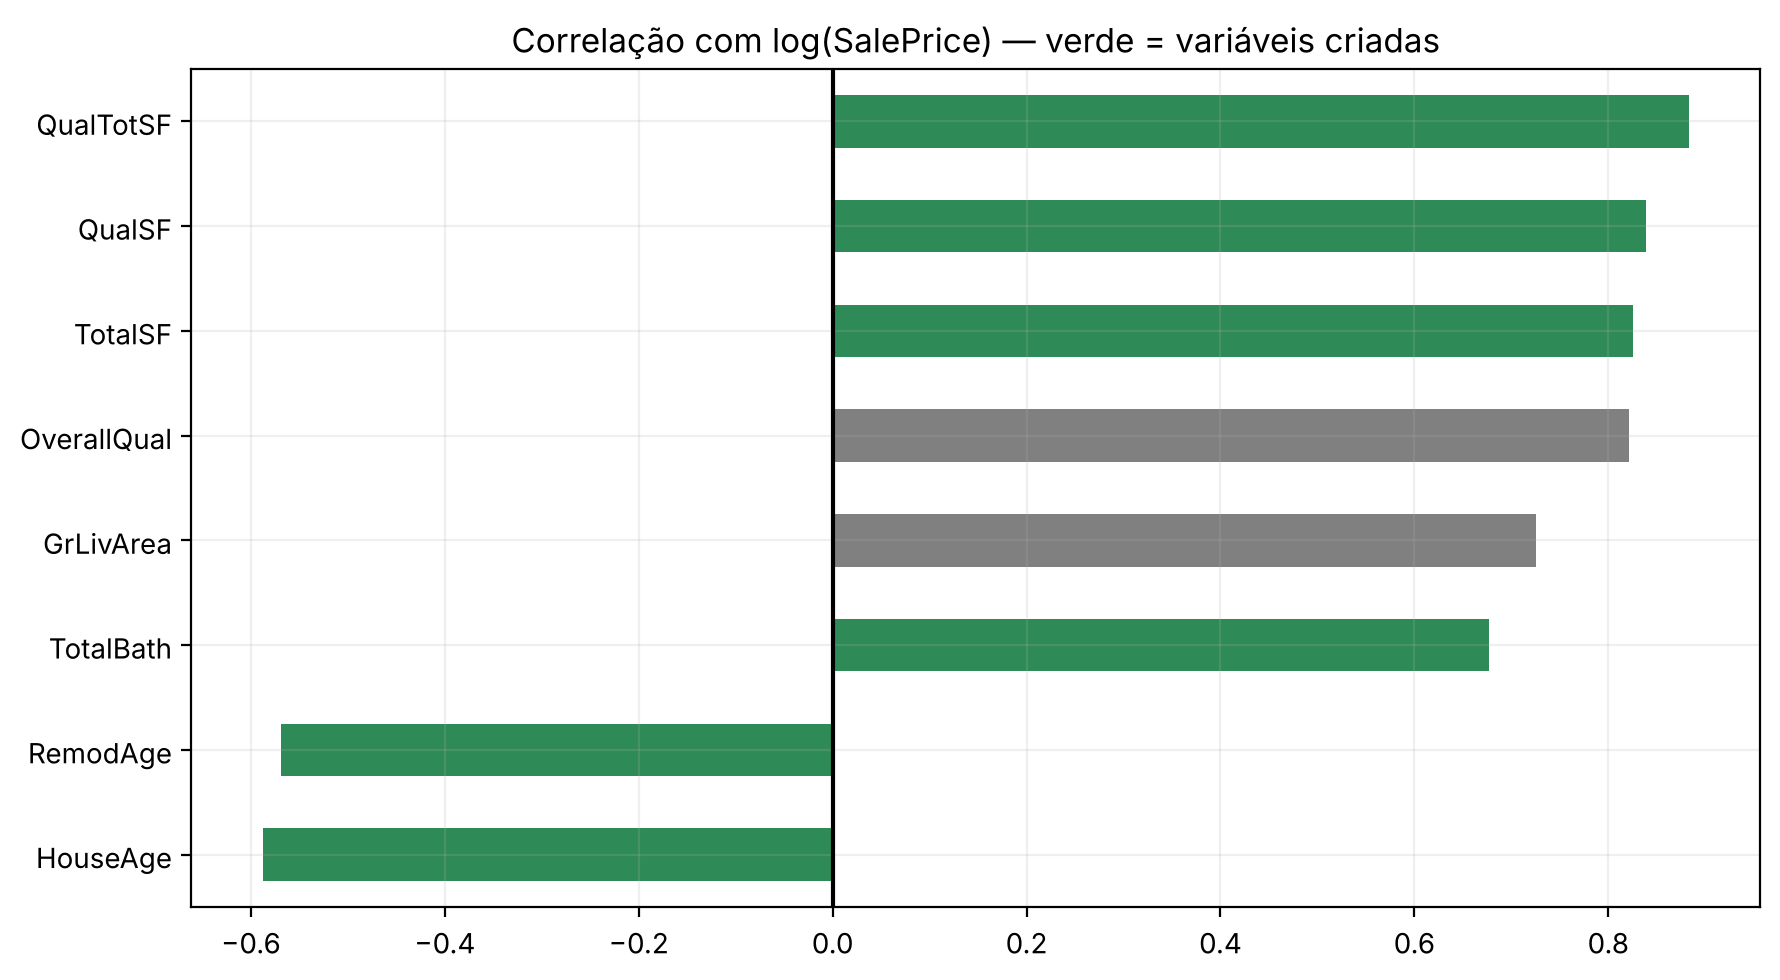

In [10]:
comparar = ['QualTotSF', 'QualSF', 'TotalSF', 'OverallQual', 'GrLivArea', 'TotalBath', 'RemodAge', 'HouseAge']
corr_novas = dados.iloc[:n_train][comparar].corrwith(pd.Series(y)).sort_values()

plt.figure(figsize=(9, 5))
corr_novas.plot.barh(color=['seagreen' if c in NOVAS else 'gray' for c in corr_novas.index])
plt.axvline(0, color='k')
plt.title('Correlação com log(SalePrice) — verde = variáveis criadas')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


A variável criada `QualTotSF` (qualidade × área total) é **mais correlacionada com o preço do que qualquer variável original**.

## 7. Codificação das variáveis

As variáveis categóricas são convertidas em colunas 0/1 (*one-hot encoding*). Duas matrizes são geradas:

- **Matriz para árvores:** one-hot apenas. Árvores fazem cortes do tipo "x ≥ valor" e não dependem da escala.
- **Matriz para modelos lineares, SVR e rede neural:** além do one-hot, as variáveis numéricas muito assimétricas (|assimetria| > 0,5 no treino) recebem a transformação Box-Cox:

\[ x' = \frac{(1 + x)^{\lambda} - 1}{\lambda}, \quad \lambda = 0{,}15 \]

Essa transformação aproxima as variáveis de uma distribuição simétrica, o que favorece modelos lineares. A padronização desses modelos é feita dentro de cada treino (`RobustScaler` em um *pipeline*), sem utilizar o conjunto de validação.


In [11]:
X_arv_all = pd.get_dummies(dados).astype(float)

lin = dados.copy()
numericas = lin.select_dtypes('number').columns
assimetria = lin.iloc[:n_train][numericas].apply(lambda s: skew(s)).abs()
assimetricas = assimetria[assimetria > 0.5].index
for c in assimetricas:
    lin[c] = boxcox1p(lin[c].clip(lower=0), 0.15)
X_lin_all = pd.get_dummies(lin).astype(float)

# Remove colunas 0/1 que aparecem em no máximo 2 casas do treino
raras = [c for c in X_lin_all.columns
         if X_lin_all.iloc[:n_train][c].nunique() == 2 and X_lin_all.iloc[:n_train][c].sum() <= 2]
X_lin_all = X_lin_all.drop(columns=raras)

X_arv, X_arv_test = X_arv_all.iloc[:n_train].values, X_arv_all.iloc[n_train:].values
X_lin, X_lin_test = X_lin_all.iloc[:n_train].values, X_lin_all.iloc[n_train:].values

assert len(X_arv) == len(y) and len(X_lin) == len(y)
assert len(X_arv_test) == len(test) and len(X_lin_test) == len(test)
print(f'Matriz para árvores: {X_arv.shape}')
print(f'Matriz para lineares: {X_lin.shape} | variáveis com Box-Cox: {len(assimetricas)}')


Matriz para árvores: (1458, 273)
Matriz para lineares: (1458, 247) | variáveis com Box-Cox: 48


## 8. Estratégia de validação

Com apenas 1.458 casas, uma única divisão treino/validação depende muito da sorte do sorteio. Por isso, todos os modelos são avaliados com **validação cruzada de 5 partes** (*5-fold*):

1. os dados são divididos em 5 partes;
2. o modelo é treinado com 4 partes e avaliado na parte restante;
3. o processo se repete 5 vezes, até que cada casa tenha sido prevista uma vez por um modelo que **não a viu** no treinamento.

As previsões obtidas dessa forma são chamadas de *out-of-fold* e serão usadas para combinar os modelos na Seção 13. A métrica é o RMSE em log, igual ao da competição.


In [12]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def avaliar(modelo, X):
    oof = np.zeros(len(y))
    notas = []
    inicio = time.time()
    for idx_tr, idx_va in kf.split(X):
        m = clone(modelo).fit(X[idx_tr], y[idx_tr])
        oof[idx_va] = m.predict(X[idx_va])
        notas.append(rmse(oof[idx_va], y[idx_va]))
    return {'RMSE_CV': np.mean(notas), 'desvio': np.std(notas),
            'tempo_s': time.time() - inicio, 'oof': oof}

resultados = {}


## 9. Árvore de decisão

O algoritmo pedido no enunciado é a **árvore de decisão**. Uma árvore sem limite de crescimento decora o treinamento (sobreajuste). Os hiperparâmetros `max_depth` (profundidade máxima) e `min_samples_leaf` (mínimo de casas por folha) são escolhidos com `GridSearchCV`, usando a mesma validação cruzada.


Melhores hiperparâmetros: {'max_depth': 10, 'min_samples_leaf': 10}
RMSE (validação cruzada): 0.1674


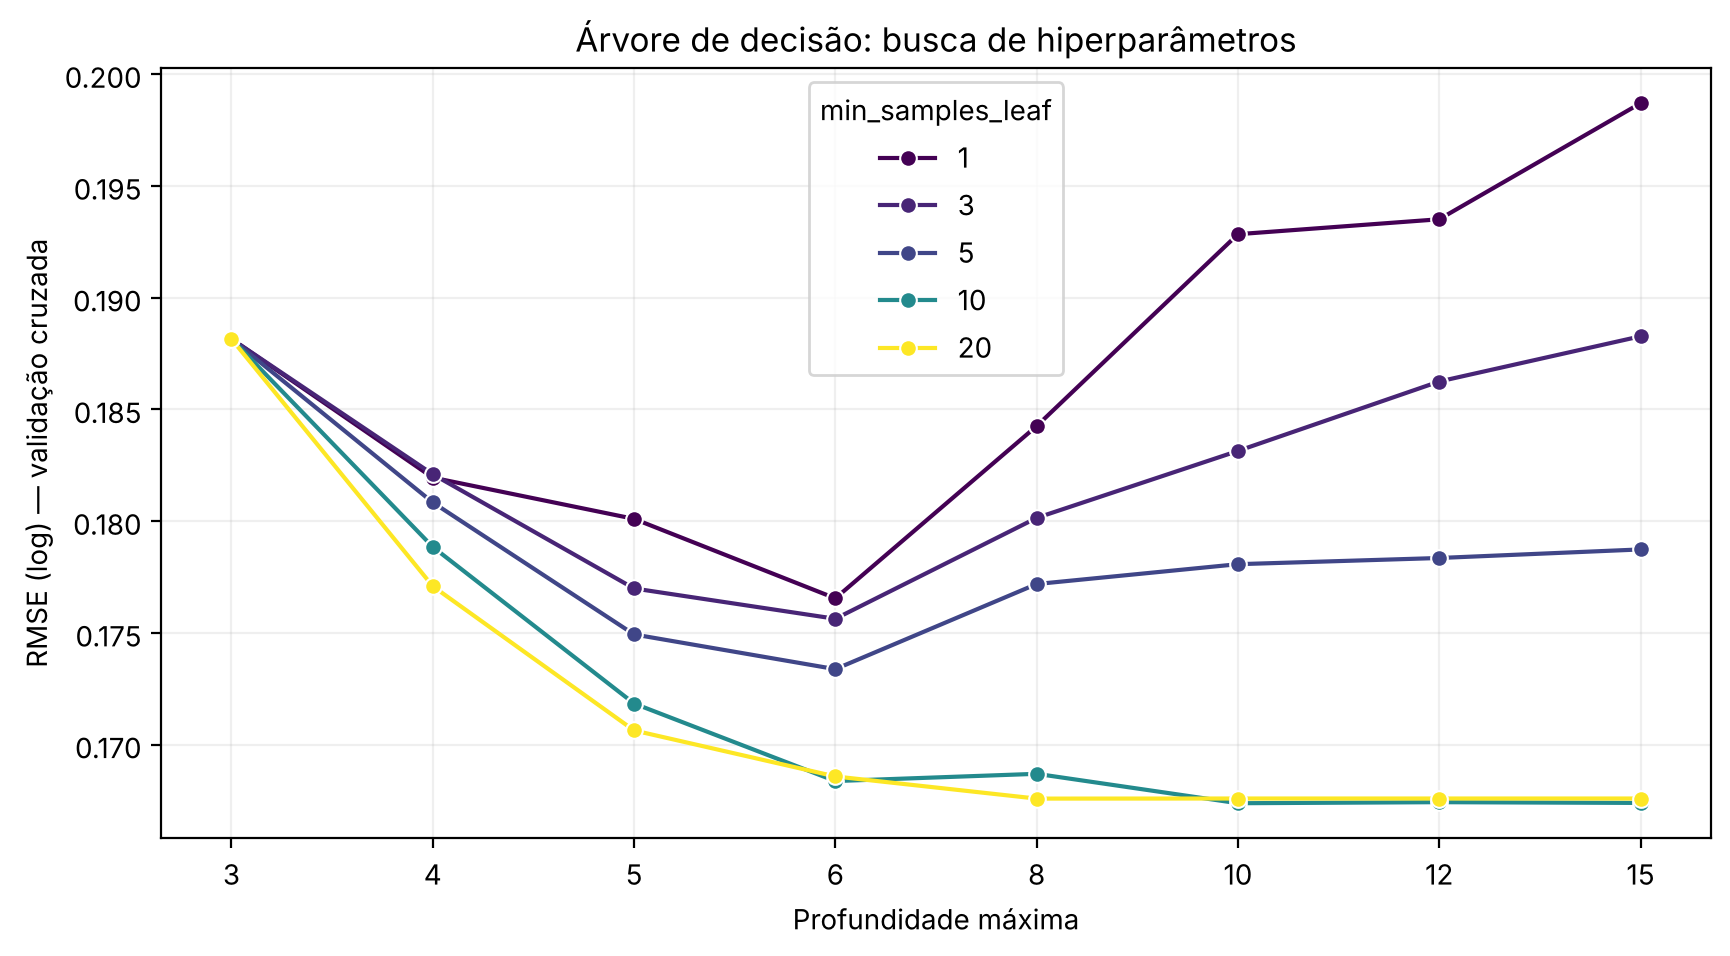

In [13]:
grade = {'max_depth': [3, 4, 5, 6, 8, 10, 12, 15, None],
         'min_samples_leaf': [1, 3, 5, 10, 20]}
busca = GridSearchCV(DecisionTreeRegressor(random_state=SEED), grade,
                     scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1).fit(X_arv, y)
print('Melhores hiperparâmetros:', busca.best_params_)
print(f'RMSE (validação cruzada): {-busca.best_score_:.4f}')

g = pd.DataFrame(busca.cv_results_)
g['max_depth'] = g['param_max_depth'].astype(str)
g['RMSE'] = -g['mean_test_score']
plt.figure(figsize=(10, 5))
sns.lineplot(data=g, x='max_depth', y='RMSE', hue='param_min_samples_leaf',
             marker='o', palette='viridis', sort=False)
plt.xlabel('Profundidade máxima')
plt.ylabel('RMSE (log) — validação cruzada')
plt.title('Árvore de decisão: busca de hiperparâmetros')
plt.legend(title='min_samples_leaf')
plt.grid(alpha=0.2)
plt.show()

resultados['Árvore de Decisão'] = avaliar(DecisionTreeRegressor(**busca.best_params_, random_state=SEED), X_arv)


## 10. Ensembles de árvores

Uma árvore isolada é instável: pequenas mudanças nos dados mudam muito a árvore. Os ensembles combinam centenas de árvores:

| Modelo | Como as árvores são combinadas |
|---|---|
| Random Forest | árvores independentes, cada uma com uma amostra diferente; média das previsões (*bagging*) |
| Extra Trees | como a Random Forest, mas com cortes sorteados |
| Gradient Boosting | árvores em **sequência**: cada nova árvore corrige o erro das anteriores |
| XGBoost | Gradient Boosting com regularização e otimizações de velocidade |
| LightGBM | Gradient Boosting que cresce as árvores folha a folha |

Os hiperparâmetros do Gradient Boosting, XGBoost e LightGBM partem das configurações usadas em soluções públicas bem colocadas da competição (ver Referências) e foram conferidos na nossa validação cruzada.


In [14]:
MODELOS_ARVORE = {
    'Random Forest': RandomForestRegressor(n_estimators=500, max_features=0.3, n_jobs=-1, random_state=SEED),
    'Extra Trees': ExtraTreesRegressor(n_estimators=500, max_features=0.3, n_jobs=-1, random_state=SEED),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=3000, learning_rate=0.02, max_depth=4,
                                                   max_features='sqrt', min_samples_leaf=15,
                                                   min_samples_split=10, loss='huber',
                                                   subsample=0.8, random_state=SEED),
    'XGBoost': XGBRegressor(n_estimators=3000, learning_rate=0.01, max_depth=3, subsample=0.7,
                            colsample_bytree=0.5, reg_alpha=0.005, n_jobs=-1, random_state=SEED),
    'LightGBM': LGBMRegressor(objective='regression', num_leaves=6, learning_rate=0.01, n_estimators=4000,
                              max_bin=200, bagging_fraction=0.75, bagging_freq=5, feature_fraction=0.25,
                              min_data_in_leaf=6, verbose=-1, random_state=SEED),
}

for nome, modelo in MODELOS_ARVORE.items():
    resultados[nome] = avaliar(modelo, X_arv)
    r = resultados[nome]
    print(f"{nome:18s} RMSE = {r['RMSE_CV']:.4f} ± {r['desvio']:.4f}  ({r['tempo_s']:.0f}s)")


Random Forest      RMSE = 0.1293 ± 0.0074  (11s)


Extra Trees        RMSE = 0.1270 ± 0.0066  (11s)


Gradient Boosting  RMSE = 0.1116 ± 0.0086  (44s)


XGBoost            RMSE = 0.1118 ± 0.0061  (8s)


LightGBM           RMSE = 0.1131 ± 0.0074  (10s)


## 11. Modelos complementares: lineares regularizados e SVR

Para o ensemble funcionar bem, os modelos combinados devem **errar em casas diferentes**. Por isso também são avaliados modelos de outras famílias, todos com a matriz Box-Cox:

- **Lasso** e **ElasticNet**: regressão linear com penalização, que zera ou reduz coeficientes de variáveis pouco úteis;
- **Ridge**: regressão linear com penalização L2;
- **Kernel Ridge** e **SVR**: modelos de núcleo, capazes de capturar relações não lineares suaves.


In [15]:
MODELOS_COMPLEMENTARES = {
    'Lasso': make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)),
    'ElasticNet': make_pipeline(RobustScaler(), ElasticNet(alpha=0.0006, l1_ratio=0.8, max_iter=50000)),
    'Ridge': make_pipeline(RobustScaler(), RidgeCV(alphas=np.logspace(-1, 2.5, 40))),
    'Kernel Ridge': make_pipeline(RobustScaler(), KernelRidge(alpha=0.6, kernel='polynomial', degree=2, coef0=2.5)),
    'SVR': make_pipeline(RobustScaler(), SVR(C=20, epsilon=0.008, gamma=0.0003)),
}

for nome, modelo in MODELOS_COMPLEMENTARES.items():
    resultados[nome] = avaliar(modelo, X_lin)
    r = resultados[nome]
    print(f"{nome:18s} RMSE = {r['RMSE_CV']:.4f} ± {r['desvio']:.4f}  ({r['tempo_s']:.0f}s)")


Lasso              RMSE = 0.1116 ± 0.0075  (0s)


ElasticNet         RMSE = 0.1117 ± 0.0075  (0s)


Ridge              RMSE = 0.1150 ± 0.0089  (1s)


Kernel Ridge       RMSE = 0.1128 ± 0.0084  (0s)


SVR                RMSE = 0.1118 ± 0.0095  (1s)


## 12. Comparação de otimizadores em uma rede neural

Também é treinada uma rede neural (MLP), seguindo o mesmo fluxo do notebook de consumo de combustível: padronização com estatísticas do treino, camada de saída com **um neurônio sem ativação** e perda **MSE**.

São comparados seis otimizadores, mantendo fixos a arquitetura, os dados e a semente. Para cada otimizador são testadas três taxas de aprendizado, e a melhor é escolhida pela validação. Os dados são divididos em 80% treino e 20% validação. O alvo é centralizado (log do preço menos a média do treino) para que todos os otimizadores partam do mesmo ponto.


In [16]:
X_tr_nn, X_va_nn, y_tr_nn, y_va_nn = train_test_split(X_lin, y, test_size=0.20, random_state=SEED)

escala = StandardScaler().fit(X_tr_nn)          # estatísticas somente do treino
X_tr_nn = escala.transform(X_tr_nn).astype('float32')
X_va_nn = escala.transform(X_va_nn).astype('float32')
y_media = y_tr_nn.mean()

def criar_rede(seed=SEED):
    tf.random.set_seed(seed)
    np.random.seed(seed)
    reg = tf.keras.regularizers.l2(1e-3)
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_tr_nn.shape[1],)),
        tf.keras.layers.Dense(64, activation='relu', kernel_regularizer=reg),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation='relu', kernel_regularizer=reg),
        tf.keras.layers.Dense(1)
    ])

OTIMIZADORES = {
    'SGD':          lambda lr: tf.keras.optimizers.SGD(learning_rate=lr),
    'SGD+Momentum': lambda lr: tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
    'RMSprop':      lambda lr: tf.keras.optimizers.RMSprop(learning_rate=lr),
    'Adam':         lambda lr: tf.keras.optimizers.Adam(learning_rate=lr),
    'Nadam':        lambda lr: tf.keras.optimizers.Nadam(learning_rate=lr),
    'AdamW':        lambda lr: tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4),
}

res_nn, curvas_nn = [], {}
for nome, criar_otimizador in OTIMIZADORES.items():
    melhor = None
    for lr in [1e-4, 1e-3, 1e-2]:
        rede = criar_rede()
        rede.compile(optimizer=criar_otimizador(lr), loss='mse')
        inicio = time.time()
        history = rede.fit(X_tr_nn, y_tr_nn - y_media,
                           validation_data=(X_va_nn, y_va_nn - y_media),
                           epochs=300, batch_size=32, verbose=0,
                           callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=25,
                                                                       restore_best_weights=True),
                                      tf.keras.callbacks.TerminateOnNaN()])
        pred = rede.predict(X_va_nn, verbose=0).ravel() + y_media
        nota = rmse(pred, y_va_nn) if np.all(np.isfinite(pred)) else np.inf
        if melhor is None or nota < melhor['RMSE_val']:
            melhor = {'otimizador': nome, 'lr': lr, 'RMSE_val': nota,
                      'épocas': len(history.history['loss']), 'tempo_s': time.time() - inicio}
            curvas_nn[nome] = history.history['val_loss']
    res_nn.append(melhor)
    print(f"{nome:13s} melhor taxa = {melhor['lr']:g} | RMSE val = {melhor['RMSE_val']:.4f} | {melhor['épocas']} épocas")

res_nn = pd.DataFrame(res_nn).set_index('otimizador').sort_values('RMSE_val')


SGD           melhor taxa = 0.01 | RMSE val = 0.1389 | 300 épocas


SGD+Momentum  melhor taxa = 0.01 | RMSE val = 0.1314 | 300 épocas


RMSprop       melhor taxa = 0.0001 | RMSE val = 0.1236 | 300 épocas


Adam          melhor taxa = 0.001 | RMSE val = 0.1265 | 194 épocas


Nadam         melhor taxa = 0.001 | RMSE val = 0.1190 | 180 épocas


AdamW         melhor taxa = 0.01 | RMSE val = 0.1258 | 73 épocas


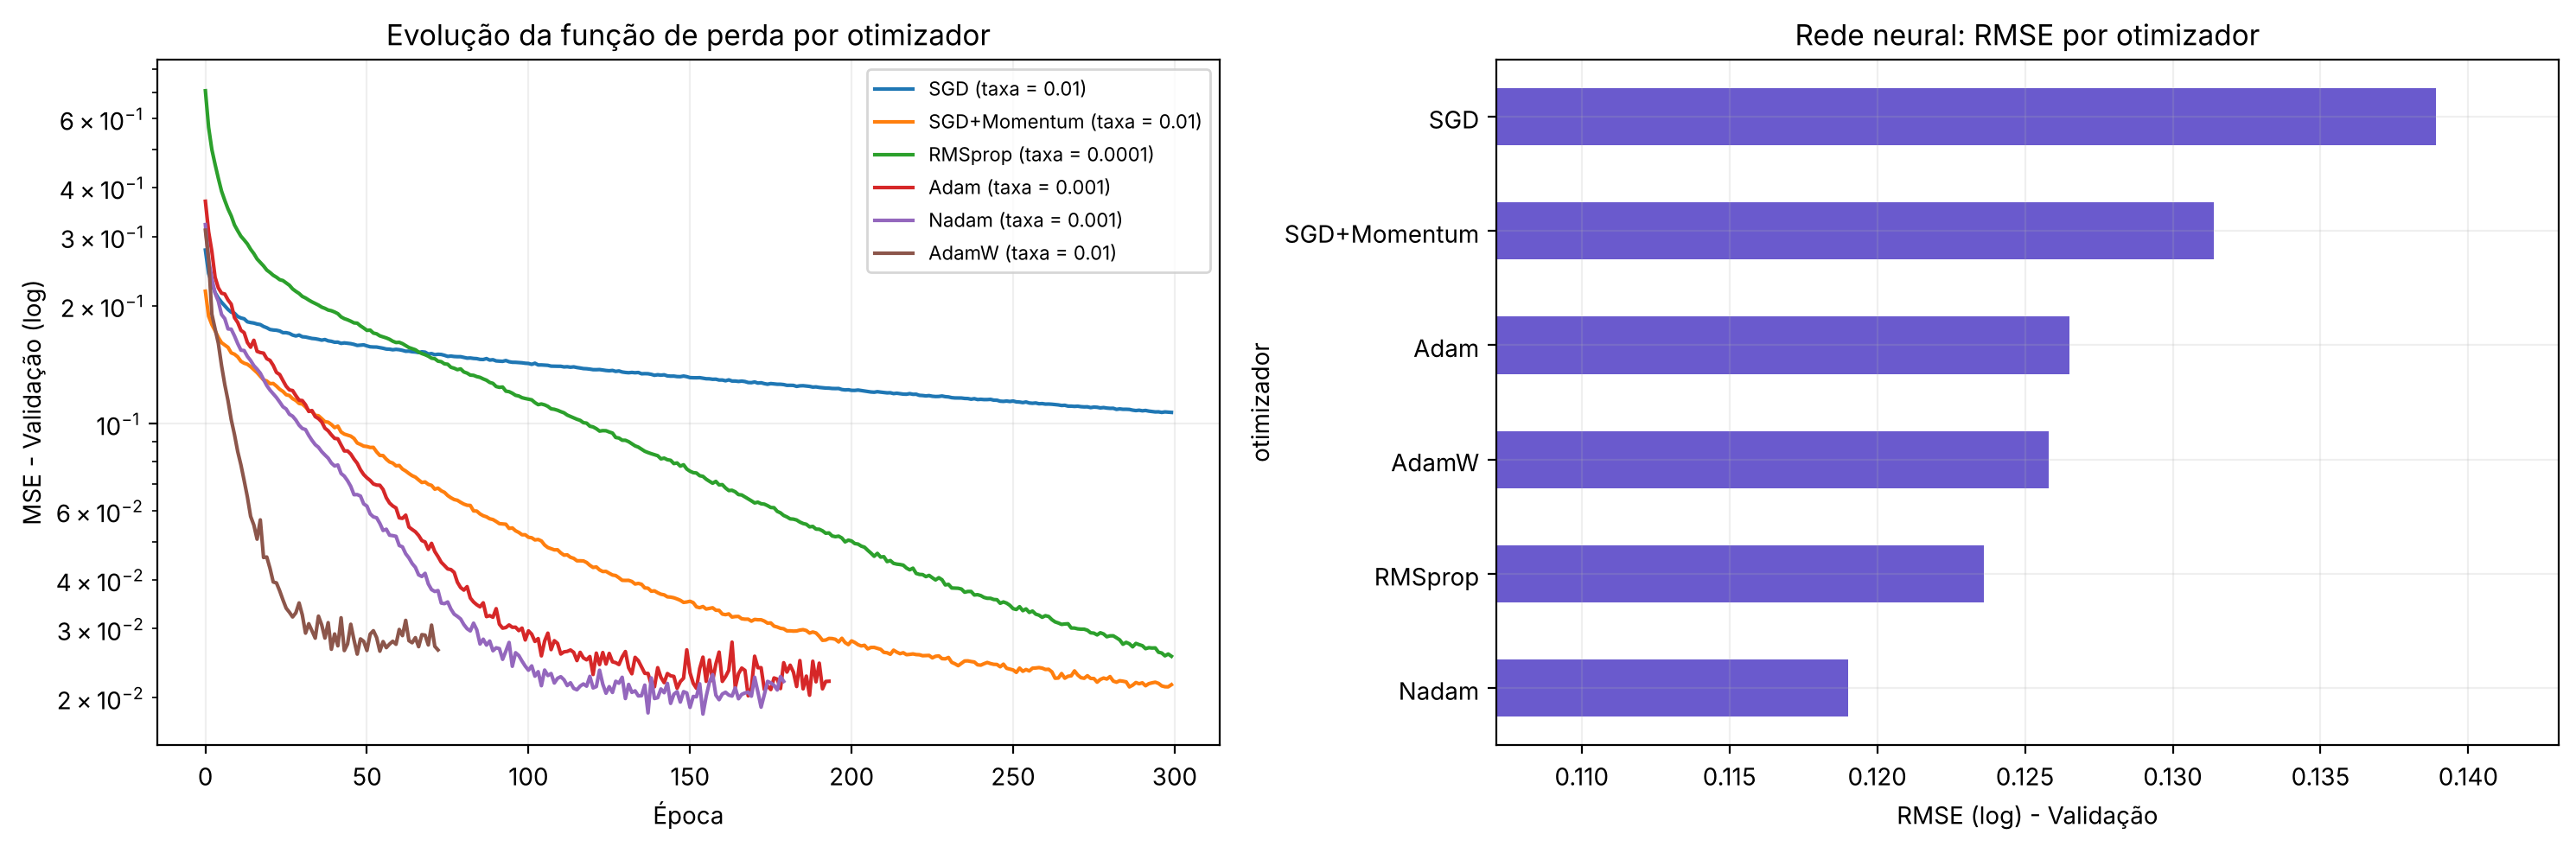

,lr,RMSE_val,épocas,tempo_s
otimizador,,,,
Nadam,0.0010,0.1190,180,32.3679
RMSprop,0.0001,0.1236,300,50.6360
AdamW,0.0100,0.1258,73,14.3021
Adam,0.0010,0.1265,194,32.3937
SGD+Momentum,0.0100,0.1314,300,46.4931
SGD,0.0100,0.1389,300,49.5276


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for nome, curva in curvas_nn.items():
    axes[0].plot(curva, label=f"{nome} (taxa = {res_nn.loc[nome, 'lr']:g})")
axes[0].set_yscale('log')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('MSE - Validação (log)')
axes[0].set_title('Evolução da função de perda por otimizador')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

res_nn['RMSE_val'].plot.barh(ax=axes[1], color='slateblue')
axes[1].set_xlim(res_nn['RMSE_val'].min() * 0.9, res_nn['RMSE_val'].max() * 1.03)
axes[1].set_xlabel('RMSE (log) - Validação')
axes[1].set_title('Rede neural: RMSE por otimizador')
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(res_nn.round(4))


O **Nadam** foi o melhor otimizador (RMSE 0,1190) e o **SGD** puro o pior (0,1389, ainda sem convergir em 300 épocas). O momentum melhorou o SGD, e os otimizadores adaptativos (Adam, AdamW, Nadam, RMSprop) ficaram à frente dos dois.

Mesmo com o melhor otimizador, a rede neural ficou atrás do Gradient Boosting, do XGBoost e do Lasso (≈ 0,112 na validação cruzada). Com 1.458 casas e quase 250 colunas, árvores e modelos lineares regularizados aproveitam melhor os dados. Por isso a rede **não entra no ensemble final**.

*Observação:* a rede foi avaliada em uma divisão 80/20, e não em 5-fold; os valores são próximos, mas não exatamente comparáveis aos da validação cruzada.


## 13. Ensemble final

Cada modelo erra em casas diferentes; combinando as previsões, parte dos erros se compensa. A previsão final é uma média ponderada:

\[ \hat{y} = \sum_{k} w_k \, \hat{y}_k, \quad w_k \ge 0, \quad \sum_k w_k = 1 \]

Os pesos \( w_k \) são encontrados por **mínimos quadrados não negativos** (NNLS) sobre as previsões *out-of-fold* — ou seja, sem olhar o conjunto de teste. Para não superestimar o resultado, a nota do ensemble também é calculada de forma **honesta**: os pesos são aprendidos em 4/5 das casas e avaliados na 1/5 restante.

São montados dois ensembles:
- **somente árvores**, caso a entrega exija exclusivamente modelos de árvore;
- **completo**, com árvores e modelos complementares (submissão principal).


In [18]:
OOF = pd.DataFrame({nome: r['oof'] for nome, r in resultados.items()})

def pesos_nnls(colunas, idx=None):
    A = OOF[colunas].values
    if idx is not None:
        A, alvo = A[idx], y[idx]
    else:
        alvo = y
    w, _ = nnls(A, alvo)
    return w / w.sum()

def nota_honesta(colunas):
    pred = np.zeros(len(y))
    for idx_tr, idx_va in KFold(5, shuffle=True, random_state=7).split(OOF):
        pred[idx_va] = OOF[colunas].values[idx_va] @ pesos_nnls(colunas, idx_tr)
    return rmse(pred, y)

ARVORES = ['Árvore de Decisão', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost', 'LightGBM']
TODOS = list(OOF.columns)

ensembles = {}
for nome, colunas in [('Ensemble só árvores', ARVORES), ('Ensemble completo', TODOS)]:
    w = pesos_nnls(colunas)
    ensembles[nome] = {'pesos': pd.Series(w, index=colunas), 'oof': OOF[colunas].values @ w}
    resultados[nome] = {'RMSE_CV': nota_honesta(colunas), 'desvio': np.nan, 'tempo_s': np.nan,
                        'oof': ensembles[nome]['oof']}
    print(f"{nome}: RMSE honesto = {resultados[nome]['RMSE_CV']:.4f}")
    pesos = ensembles[nome]['pesos']
    display(pesos[pesos > 0].sort_values(ascending=False).round(3).to_frame('peso'))


Ensemble só árvores: RMSE honesto = 0.1104


,peso
Gradient Boosting,0.51
XGBoost,0.49


Ensemble completo: RMSE honesto = 0.1075


,peso
Lasso,0.289
Gradient Boosting,0.252
XGBoost,0.250
SVR,0.209


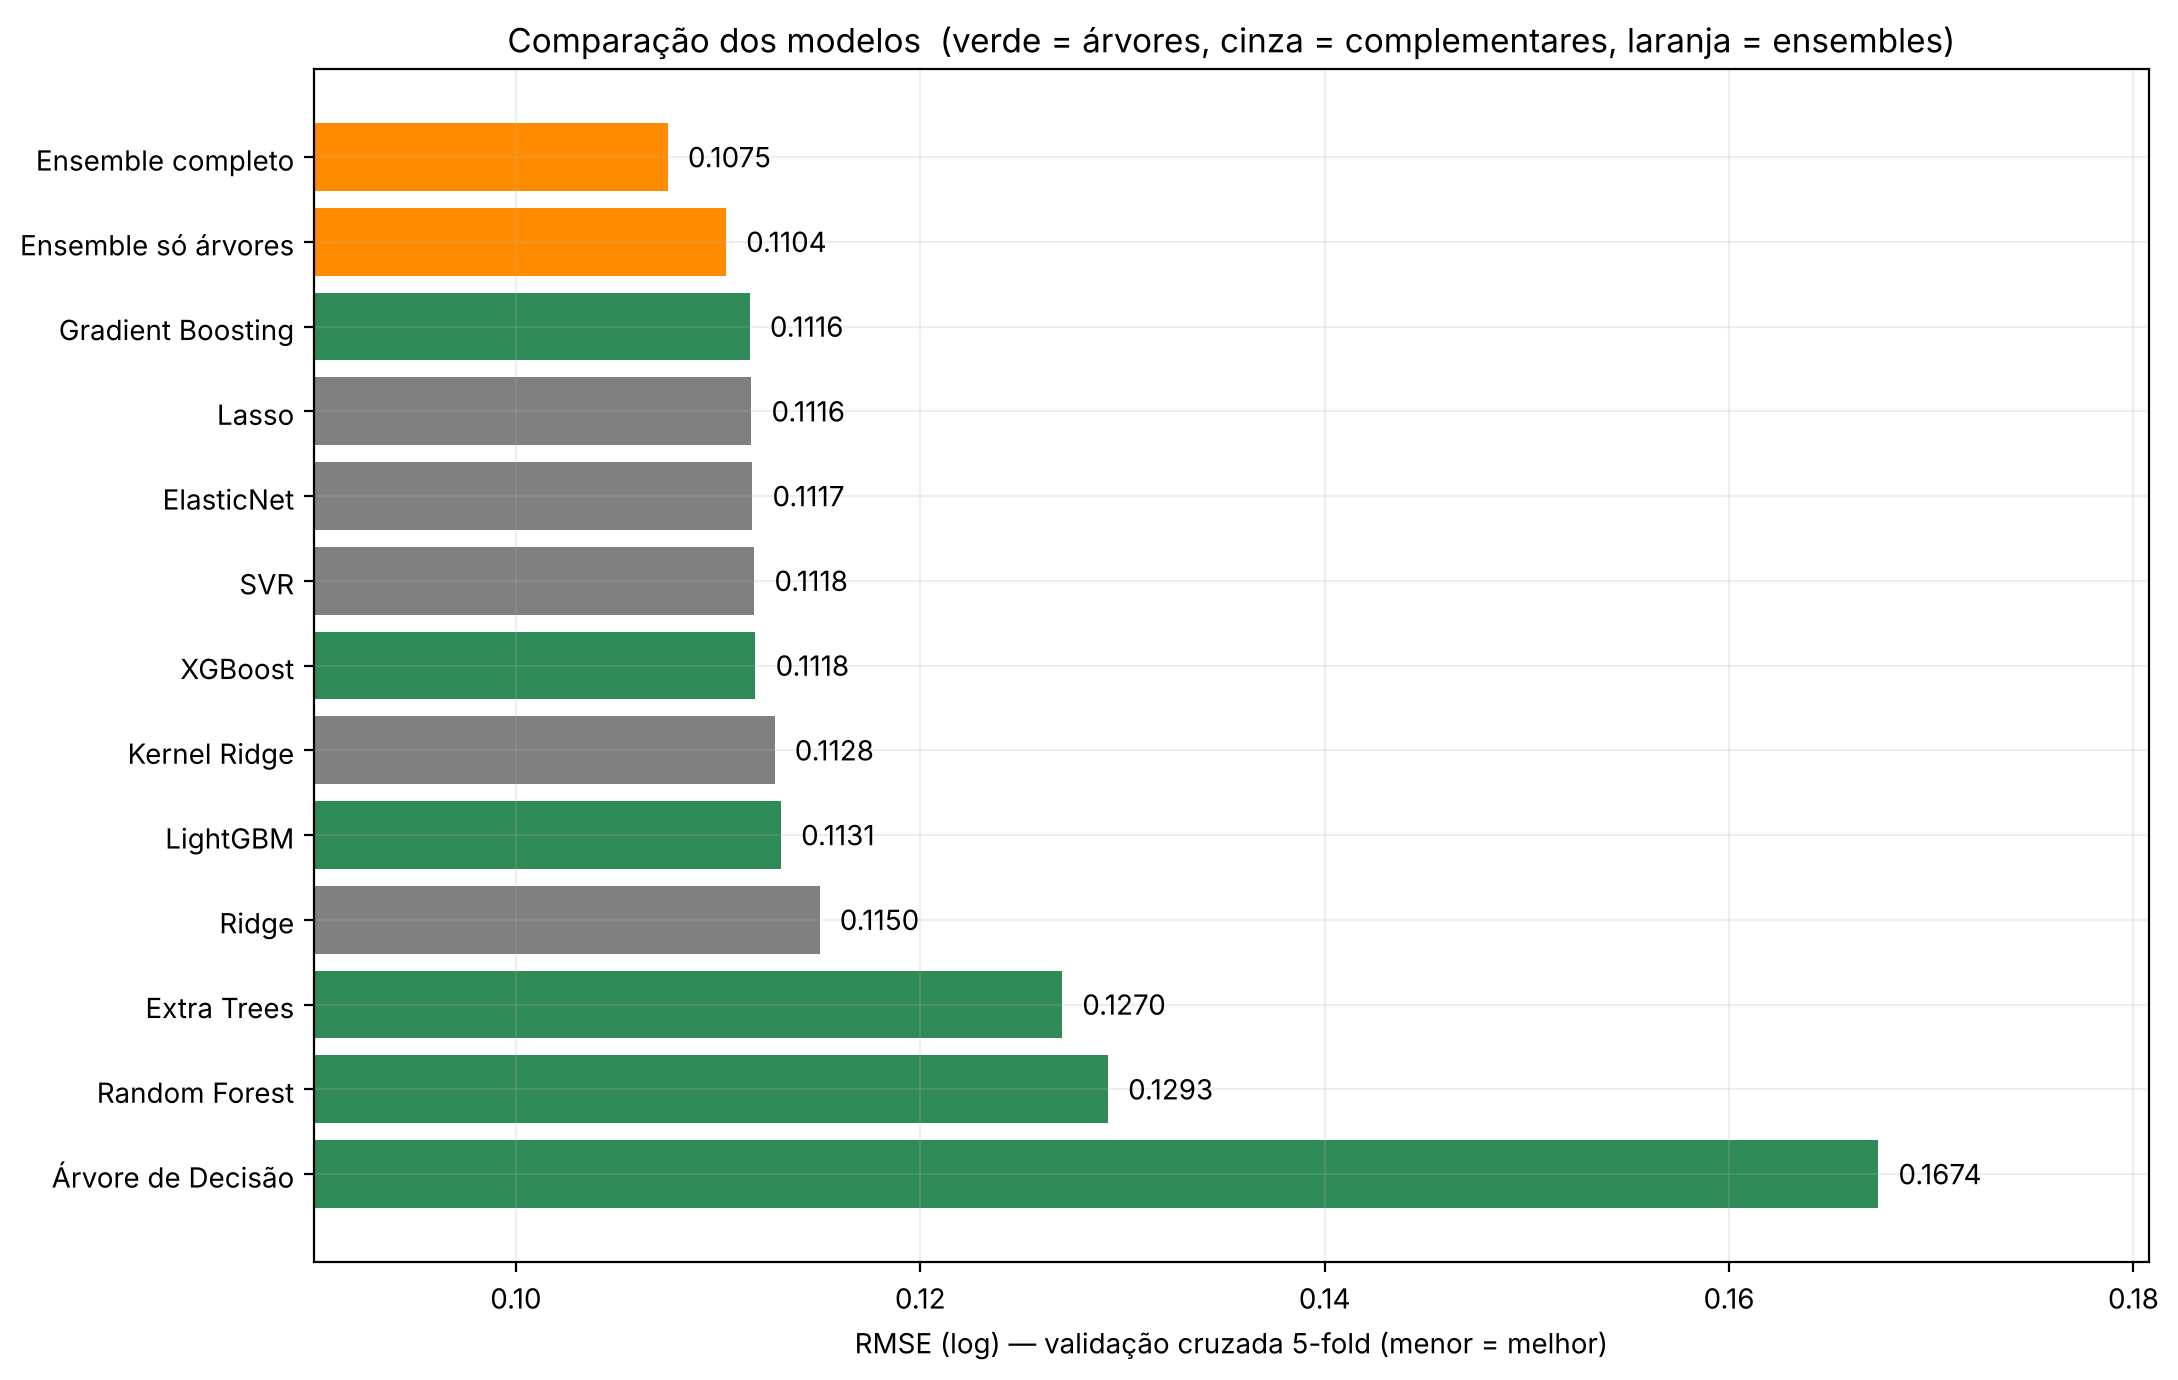

,RMSE_CV,desvio,tempo_s
Ensemble completo,0.1075,NaN,NaN
Ensemble só árvores,0.1104,NaN,NaN
Gradient Boosting,0.1116,0.0086,44.3418
Lasso,0.1116,0.0075,0.3276
ElasticNet,0.1117,0.0075,0.3069
SVR,0.1118,0.0095,1.3093
XGBoost,0.1118,0.0061,8.0775
Kernel Ridge,0.1128,0.0084,0.3995
LightGBM,0.1131,0.0074,9.9043
Ridge,0.1150,0.0089,1.0550


In [19]:
tabela = pd.DataFrame({nome: {'RMSE_CV': r['RMSE_CV'], 'desvio': r['desvio'], 'tempo_s': r['tempo_s']}
                       for nome, r in resultados.items()}).T.astype(float).sort_values('RMSE_CV')
tipo = lambda n: 'ensemble' if 'Ensemble' in n else ('árvore' if n in ARVORES else 'complementar')
cores = {'árvore': 'seagreen', 'complementar': 'gray', 'ensemble': 'darkorange'}

plt.figure(figsize=(11, 7))
ordem = tabela.iloc[::-1]
plt.barh(ordem.index, ordem['RMSE_CV'], color=[cores[tipo(n)] for n in ordem.index])
for i, v in enumerate(ordem['RMSE_CV']):
    plt.text(v + 0.001, i, f'{v:.4f}', va='center')
plt.xlim(0.09, tabela['RMSE_CV'].max() * 1.08)
plt.xlabel('RMSE (log) — validação cruzada 5-fold (menor = melhor)')
plt.title('Comparação dos modelos  (verde = árvores, cinza = complementares, laranja = ensembles)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(tabela.round(4))


## 14. Gráfico: valores reais × valores previstos

Quanto mais próximos os pontos estiverem da linha `y = x`, menor será o erro de previsão. São usadas as previsões *out-of-fold* do ensemble completo, convertidas de volta para dólares.


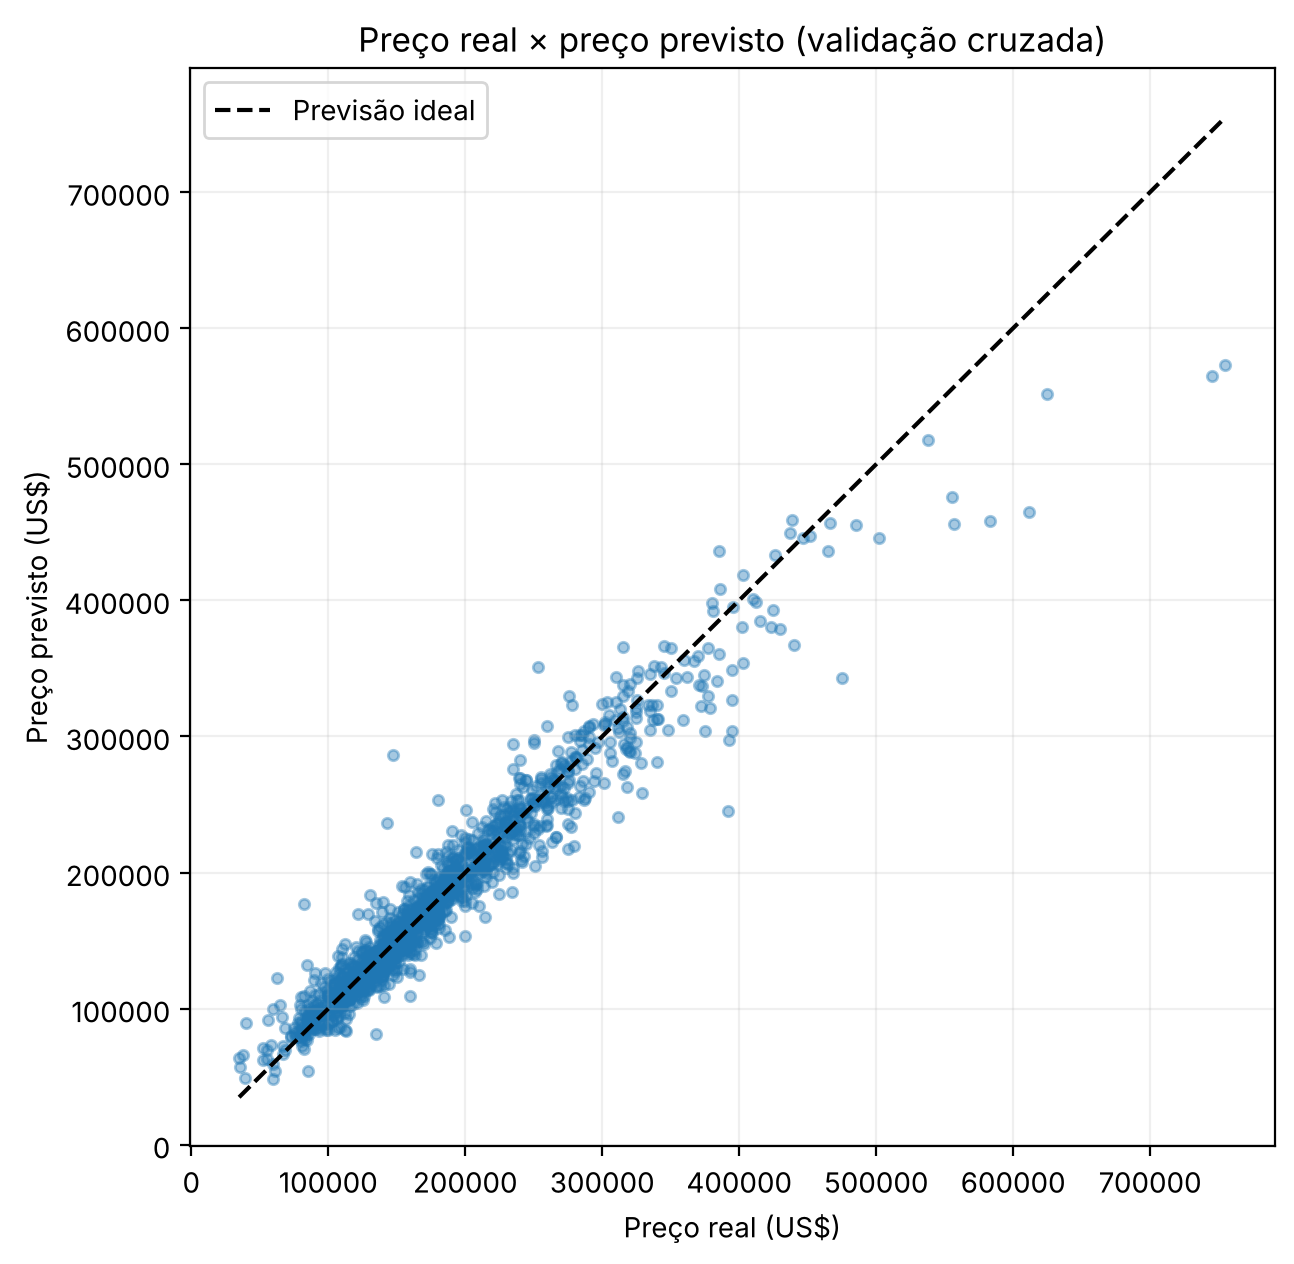

Erro percentual mediano: 5.1%
Casas com erro abaixo de 10%: 77.4%


In [20]:
real = np.expm1(y)
previsto = np.expm1(ensembles['Ensemble completo']['oof'])

plt.figure(figsize=(7, 7))
plt.scatter(real, previsto, alpha=0.4, s=14)
limites = [min(real.min(), previsto.min()), max(real.max(), previsto.max())]
plt.plot(limites, limites, '--', color='k', label='Previsão ideal')
plt.xlabel('Preço real (US$)')
plt.ylabel('Preço previsto (US$)')
plt.title('Preço real × preço previsto (validação cruzada)')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

erro_pct = np.abs(previsto - real) / real * 100
print(f'Erro percentual mediano: {np.median(erro_pct):.1f}%')
print(f'Casas com erro abaixo de 10%: {(erro_pct < 10).mean() * 100:.1f}%')


## 15. Análise dos resíduos

O resíduo é definido, em escala logarítmica, como:

\[ e = \log(\hat{y}) - \log(y) \]

A distribuição dos resíduos ajuda a identificar faixas de preço nas quais o modelo apresenta erros sistemáticos.


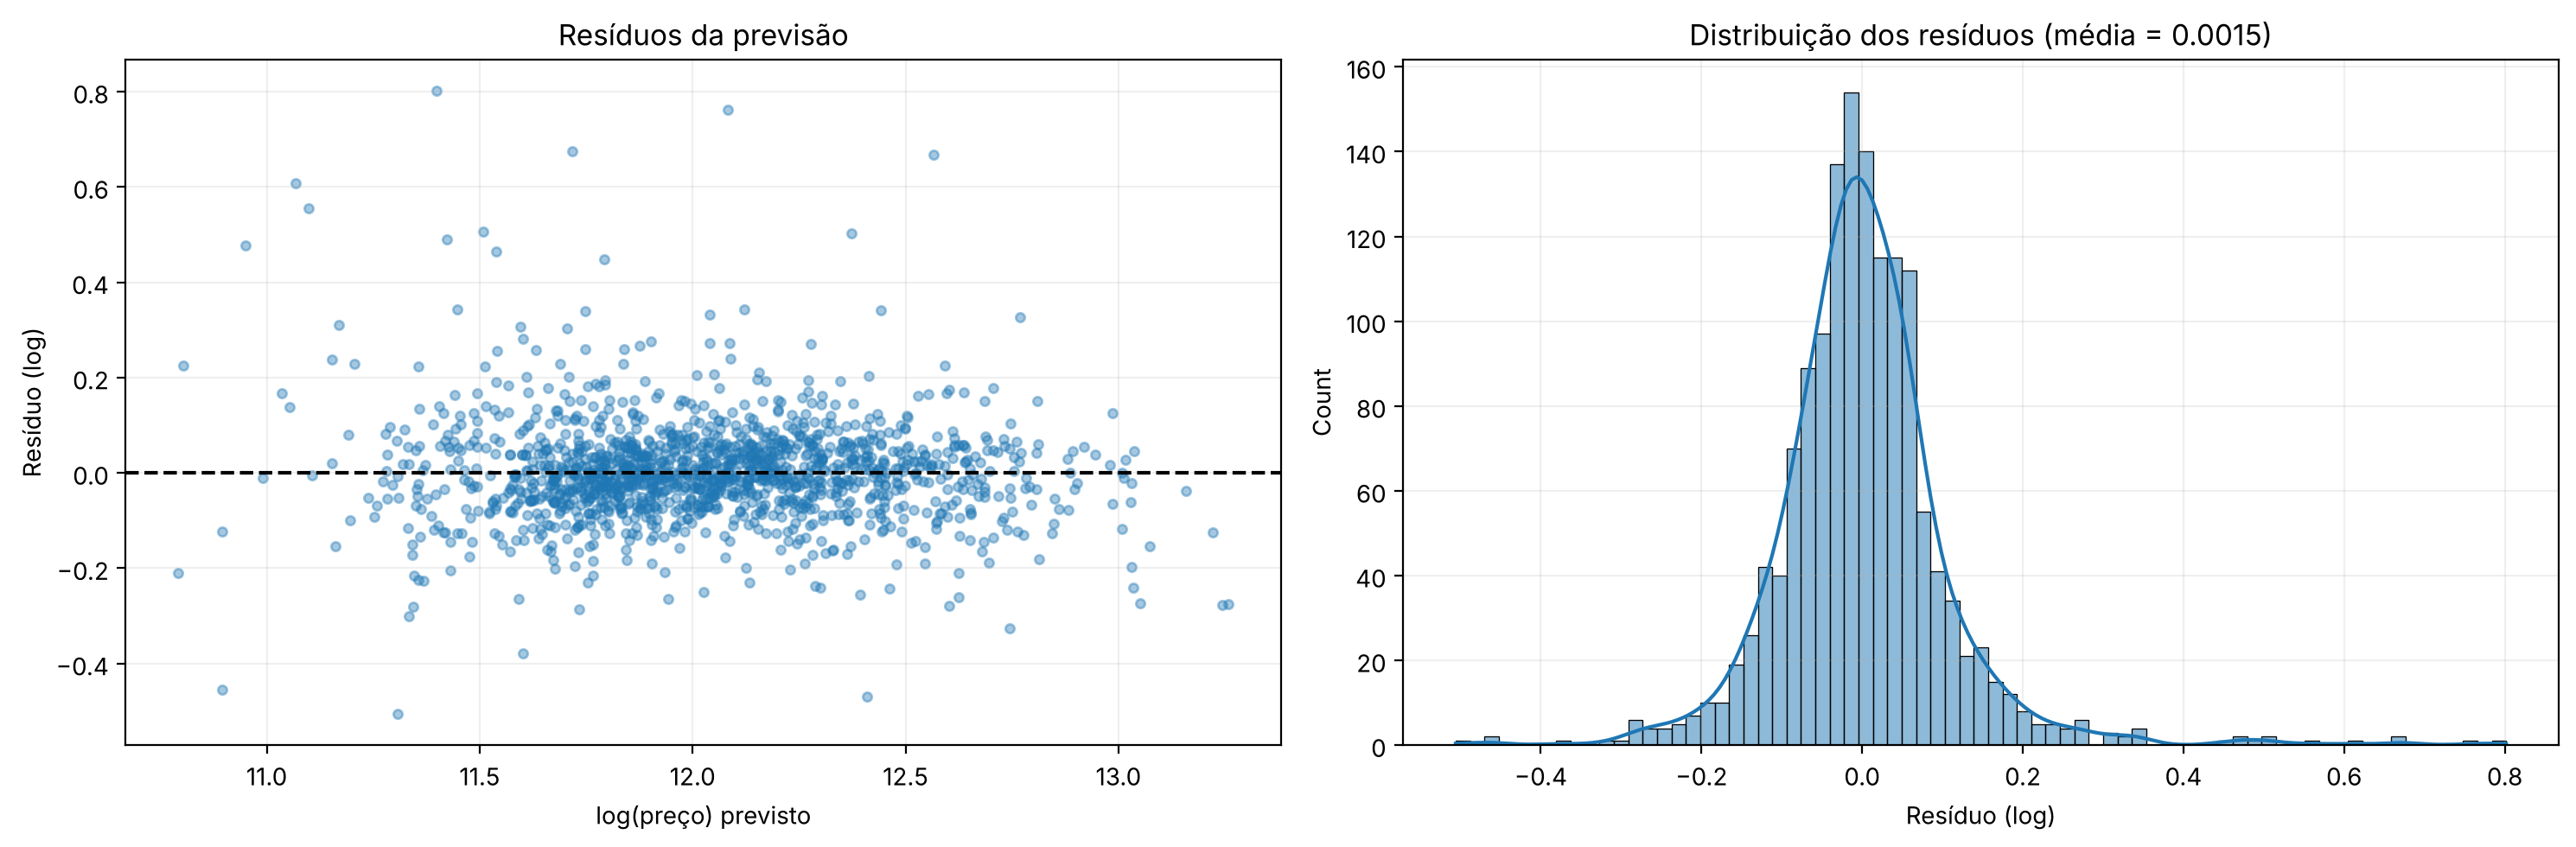

In [21]:
residuos = ensembles['Ensemble completo']['oof'] - y

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(ensembles['Ensemble completo']['oof'], residuos, alpha=0.4, s=14)
axes[0].axhline(0, linestyle='--', color='k')
axes[0].set_xlabel('log(preço) previsto')
axes[0].set_ylabel('Resíduo (log)')
axes[0].set_title('Resíduos da previsão')
axes[0].grid(alpha=0.2)
sns.histplot(residuos, kde=True, ax=axes[1])
axes[1].set_xlabel('Resíduo (log)')
axes[1].set_title(f'Distribuição dos resíduos (média = {residuos.mean():.4f})')
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 16. Importância das variáveis

A importância (ganho) do XGBoost mostra quais variáveis mais contribuem para os cortes das árvores. Em verde, as variáveis criadas na Seção 6.


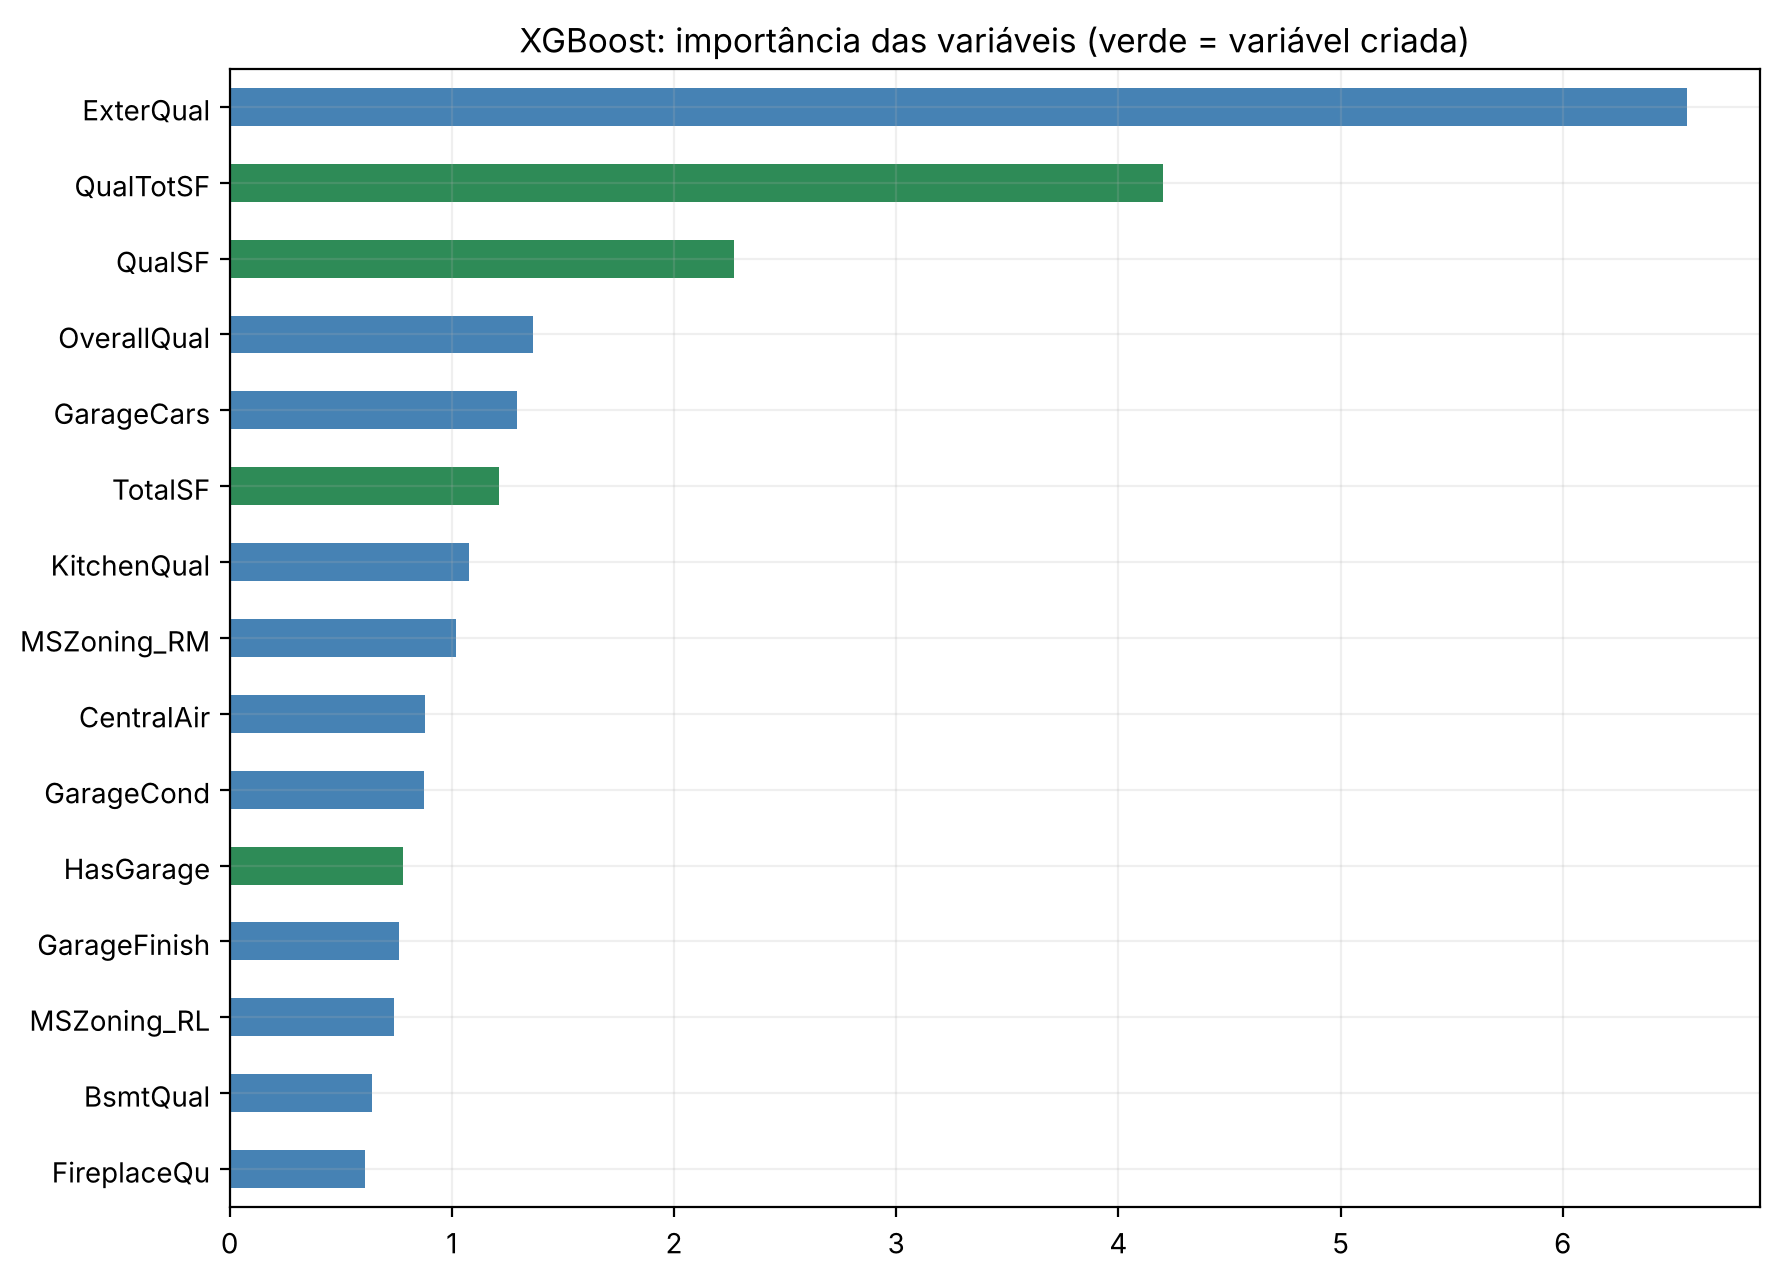

In [22]:
xgb_final = clone(MODELOS_ARVORE['XGBoost']).fit(pd.DataFrame(X_arv, columns=X_arv_all.columns), y)
importancia = pd.Series(xgb_final.get_booster().get_score(importance_type='gain')).sort_values().tail(15)

plt.figure(figsize=(9, 6.5))
importancia.plot.barh(color=['seagreen' if c in NOVAS else 'steelblue' for c in importancia.index])
plt.title('XGBoost: importância das variáveis (verde = variável criada)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 17. Treinamento final e arquivo de submissão

Cada modelo com peso positivo é treinado novamente com **todas** as casas do treinamento. As previsões do teste são combinadas com os pesos da Seção 13 e convertidas para dólares com \( e^{y} - 1 \).

São gerados dois arquivos no formato exigido (`Id,SalePrice`):
- `submission.csv` → ensemble completo (**submissão principal**);
- `submission_arvores.csv` → ensemble somente com árvores.


In [23]:
TODOS_MODELOS = {'Árvore de Decisão': DecisionTreeRegressor(**busca.best_params_, random_state=SEED),
                 **MODELOS_ARVORE, **MODELOS_COMPLEMENTARES}
previsoes_teste = {}

def prever_teste(pesos):
    log_pred = np.zeros(len(test))
    for nome, w in pesos.items():
        if w <= 0:
            continue
        if nome not in previsoes_teste:
            X_tr, X_te = (X_lin, X_lin_test) if nome in MODELOS_COMPLEMENTARES else (X_arv, X_arv_test)
            previsoes_teste[nome] = clone(TODOS_MODELOS[nome]).fit(X_tr, y).predict(X_te)
        log_pred += w * previsoes_teste[nome]
    return np.expm1(log_pred)

submission = pd.DataFrame({'Id': test_id, 'SalePrice': prever_teste(ensembles['Ensemble completo']['pesos'])})
submission_arvores = pd.DataFrame({'Id': test_id, 'SalePrice': prever_teste(ensembles['Ensemble só árvores']['pesos'])})

for s in (submission, submission_arvores):
    assert list(s.columns) == ['Id', 'SalePrice']
    assert len(s) == len(test) == 1459
    assert s['Id'].min() == 1461 and s['Id'].max() == 2919
    assert s['SalePrice'].notna().all() and (s['SalePrice'] > 0).all()

submission.to_csv('submission.csv', index=False)
submission_arvores.to_csv('submission_arvores.csv', index=False)

display(submission.head())
print(f"Preço previsto - mediana: US$ {submission['SalePrice'].median():,.0f}")
print(f"Preço real no treino - mediana: US$ {train[TARGET].median():,.0f}")


,Id,SalePrice
0,1461,121691.998789
1,1462,163068.959013
2,1463,185435.827198
3,1464,197543.939015
4,1465,191294.633177


Preço previsto - mediana: US$ 157,670
Preço real no treino - mediana: US$ 163,000


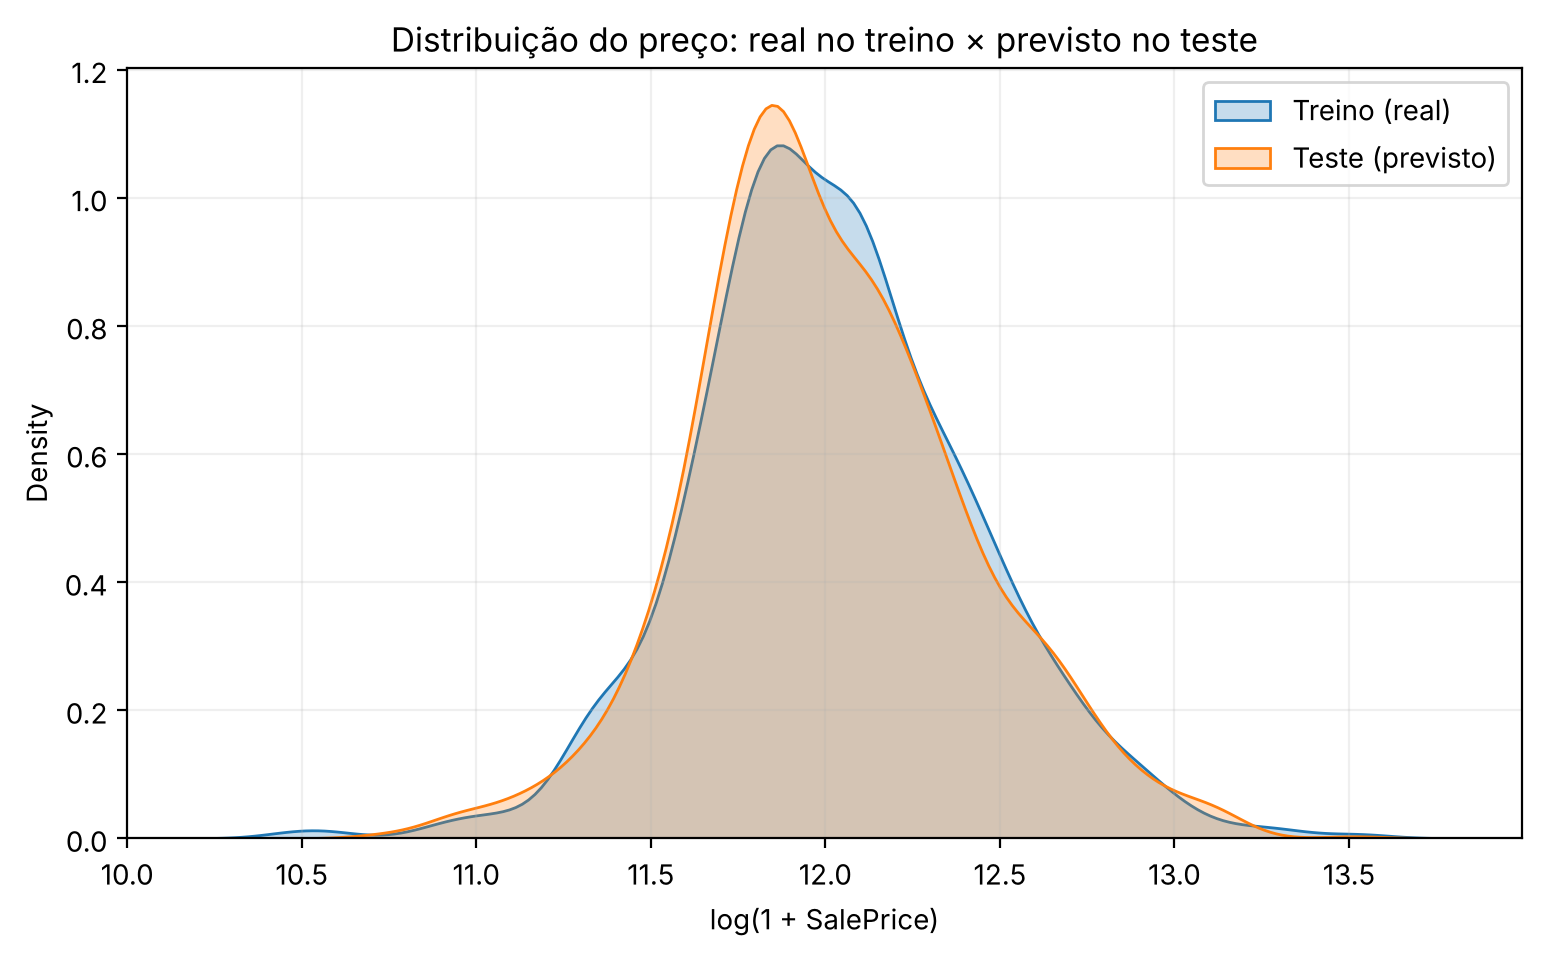

In [24]:
plt.figure(figsize=(9, 5))
sns.kdeplot(np.log1p(train[TARGET]), label='Treino (real)', fill=True)
sns.kdeplot(np.log1p(submission['SalePrice']), label='Teste (previsto)', fill=True)
plt.xlabel('log(1 + SalePrice)')
plt.title('Distribuição do preço: real no treino × previsto no teste')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## 18. Exemplo de utilização do modelo

A função abaixo recebe o `Id` de uma casa do conjunto de teste e mostra suas principais características e o preço estimado pelo ensemble.


In [25]:
def estimar_preco(id_casa):
    casa = test.loc[test['Id'] == id_casa].iloc[0]
    preco = submission.loc[submission['Id'] == id_casa, 'SalePrice'].iloc[0]
    print(f"Casa {id_casa} | bairro {casa['Neighborhood']} | qualidade {casa['OverallQual']}/10 | "
          f"{casa['GrLivArea']} pés² | construída em {casa['YearBuilt']}")
    return preco

# Exemplo
preco_estimado = estimar_preco(1461)
print(f'Preço estimado: US$ {preco_estimado:,.2f}')


Casa 1461 | bairro NAmes | qualidade 5/10 | 896 pés² | construída em 1961
Preço estimado: US$ 121,692.00


## 19. Conclusão

Neste experimento, árvores de decisão e seus ensembles foram utilizados como modelos de **regressão** para estimar `SalePrice`.

| Modelo | RMSE (log), validação cruzada |
|---|---|
| Árvore de decisão (GridSearch) | 0,1674 |
| Random Forest | 0,1293 |
| Gradient Boosting | 0,1116 |
| Ensemble só árvores (Gradient Boosting + XGBoost) | 0,1104 |
| **Ensemble completo** (Lasso, Gradient Boosting, XGBoost e SVR) | **0,1075** |

Pontos importantes do fluxo:

1. `log(1 + SalePrice)` é a variável-alvo, pois a competição avalia o erro em logaritmo.
2. Apenas 2 outliers foram removidos; as casas caras de alta qualidade permaneceram.
3. Todas as estatísticas de preenchimento e de transformação foram calculadas somente com o conjunto de treinamento.
4. A variável criada `QualTotSF` (qualidade × área total) foi a mais correlacionada com o preço.
5. Todos os modelos foram avaliados com validação cruzada 5-fold, usando a métrica da competição.
6. A árvore de decisão foi otimizada com GridSearch; os ensembles de árvores reduziram o erro em cerca de 33% em relação a ela.
7. Entre os otimizadores da rede neural, Nadam foi o melhor e SGD o pior; ainda assim, a rede não superou as árvores.
8. O ensemble final combina modelos que erram em casas diferentes e reduz o erro em 36% em relação à árvore de decisão.

A nota no placar do Kaggle é calculada com outra parte dos dados e costuma ficar um pouco acima do valor da validação cruzada.

Como atividade complementar, podem ser testadas outras variáveis derivadas e outras combinações de modelos, mantendo a mesma validação cruzada para uma comparação consistente.

**Referências**
- DE COCK, D. *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project*. Journal of Statistics Education, v. 19, n. 3, 2011.
- SERIGNE. *Stacked Regressions: Top 4% on LeaderBoard*. Kaggle, 2017. https://www.kaggle.com/serigne/stacked-regressions-top-4-on-leaderboard
- KAGGLE. *House Prices – Advanced Regression Techniques*. https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques
- CHEN, T.; GUESTRIN, C. *XGBoost: A Scalable Tree Boosting System*. KDD, 2016.
- KE, G. et al. *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS, 2017.
- SCIKIT-LEARN. *Ensemble methods*. https://scikit-learn.org/stable/modules/ensemble.html
- GÉRON, A. *Mãos à Obra: Aprendizado de Máquina com Scikit-Learn, Keras & TensorFlow*. 2. ed. Alta Books, 2021.
